Group 11
## Predicting Regions with High Electric Vehicle Adoption in India

**Business problem:** Identify regions with high electric vehicle (EV) adoption using predictive analytics to support efficient charging-infrastructure planning.

**Business context:** Governments and utility providers need to anticipate where EV adoption and therefore charging demand are likely to increase. This project uses historical Vahan vehicle-registration data to identify regions likely to have high EV adoption.

### Project framing

| Requirement | Project definition |
|---|---|
| **Identifier variables** | `state_name`, `state_code`, `office_name`, `office_code` |
| **Primary dependent variable** | 2024 EV adoption rate = EV registrations / all vehicle registrations |
| **Classification target** | `high_adoption = 1` when a state's 2024 EV adoption rate is in the top 25% of observed states |
| **Explanatory variables** | Historical EV adoption rates, EV registrations, total registrations, EV growth and adoption-rate changes from 2019–2023 |
| **Data source** | Vahan vehicle registrations by fuel type, Ministry of Road Transport & Highways (MoRTH), provided CSV |
| **Unit of analysis** | State/UT-region |
| **Prediction horizon** | Historical information available through 2023 → observed 2024 period in the data |
| **ML objective** | Predict high-adoption regions and estimate the continuous 2024 EV adoption rate |

### Important data-alignment note

The data is **Vahan vehicle registrations by fuel type** and its latest date is in **May 2024**.

The workflow follows the concepts used in the provided class notebooks: data understanding → exploratory analysis → feature engineering → train/test split → regression/classification → decision trees → Random Forest → Gradient Boosting → model comparison → feature importance → clustering/PCA for regional profiling.


## 1. Business Problem and Analytical Questions

### Business problem
Where should charging infrastructure be prioritised based on observed and predicted EV adoption?

### Analytical questions
1. Which states have the highest EV adoption rates?
2. Has historical EV adoption growth been a useful signal for future adoption?
3. Can we predict whether a region will belong to the high-EV-adoption group?
4. Which machine-learning model performs best?
5. Which historical variables are most influential?
6. Can regions be grouped into meaningful EV-adoption profiles for infrastructure planning?

### Hypotheses
- **H1:** States with higher historical EV adoption rates are more likely to have high future EV adoption.
- **H2:** Faster historical growth in EV registrations is associated with higher future EV adoption.
- **H3:** Ensemble tree models can capture non-linear relationships that a simple linear/logistic model may miss.


## 2. Data Information

The dataset contains vehicle registrations at a state/UT and RTO/office level, reported by fuel type.

### Main variables

| Variable | Meaning | Role |
|---|---|---|
| `date` | Registration period | Time variable |
| `state_name` | State/UT | Region identifier |
| `state_code` | State/UT code | Identifier |
| `office_name` | Registration office/RTO | Identifier |
| `office_code` | RTO code | Identifier |
| `fuel_type` | Fuel/powertrain type | Used to identify EVs |
| `category` | Dataset category | Descriptive |
| `registrations` | Number of registrations | Numeric measure |

For this project, an EV is identified when `fuel_type` contains **Electric**. This captures the electric-powertrain observations present in the data.


In [1]:
# 3. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, r2_score, mean_absolute_error, mean_squared_error
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Libraries loaded.")


Libraries loaded.


In [ ]:
from pathlib import Path

DATA_FILENAME = "vahan-vehicle-registrations-by-fuel-type-nmiqeb.csv"
candidate_paths = [
    Path(DATA_FILENAME),                         # same folder as notebook
    Path("../data") / DATA_FILENAME,             # repo data/ folder
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Unzip data/vahan-registrations.zip into the data/ folder."
    )

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())


Shape: (418372, 9)


,id,date,state_name,state_code,office_name,office_code,fuel_type,category,registrations
0,0,01-04-2020,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,36
1,1,01-04-2020,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Petrol,Fuel,122
2,2,01-08-2020,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,1
3,3,01-12-2020,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Diesel,Fuel,24
4,4,01-12-2020,Andaman And Nicobar Islands,35,Port Blair Dto,AN1,Electric(Bov),Fuel,2


In [3]:
# 5. Basic data understanding
print("DATA TYPES")
display(df.dtypes.to_frame("dtype"))

print("\nMISSING VALUES")
display(df.isna().sum().to_frame("missing_count"))

print("\nDESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)

print("\nUNIQUE VALUES")
for col in ["state_name", "office_name", "fuel_type", "category"]:
    print(f"{col}: {df[col].nunique()} unique values")


DATA TYPES


,dtype
id,int64
date,object
state_name,object
state_code,int64
office_name,object
office_code,object
fuel_type,object
category,object
registrations,int64



MISSING VALUES


,missing_count
id,0
date,0
state_name,0
state_code,0
office_name,0
office_code,0
fuel_type,0
category,0
registrations,0



DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"418,372.0000",NaN,NaN,NaN,"209,185.5000","120,773.7377",0.0000,"104,592.7500","209,185.5000","313,778.2500","418,371.0000"
date,418372,65,01-05-2024,9624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state_name,418372,34,Tamil Nadu,52512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state_code,"418,372.0000",NaN,NaN,NaN,19.1611,10.9680,1.0000,8.0000,21.0000,29.0000,38.0000
office_name,418372,1414,Aurangabad,934,NaN,NaN,NaN,NaN,NaN,NaN,NaN
office_code,418372,1314,MH15,575,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,418372,22,Petrol,82094,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,418372,1,Fuel,418372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registrations,"418,372.0000",NaN,NaN,NaN,"1,844.8224","55,819.8417",1.0000,5.0000,26.0000,170.0000,"15,988,691.0000"



UNIQUE VALUES


state_name: 34 unique values


office_name: 1414 unique values
fuel_type: 22 unique values
category: 1 unique values


In [ ]:
# 6. Data preparation
df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# EV definition based on the fuel-type field.
df["is_ev"] = df["fuel_type"].str.contains("electric", case=False, na=False)

print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Number of states/UTs:", df["state_name"].nunique())
print("Number of registration offices:", df["office_name"].nunique())
print("EV rows:", int(df["is_ev"].sum()))

display(df["fuel_type"].value_counts().head(15).to_frame("rows"))


Date range: 2019-01-01 to 2024-05-01
Number of states/UTs: 34


Number of registration offices: 1414
EV rows: 55305


,rows
fuel_type,
Petrol,82094
Diesel,81597
Petrol/Hybrid,59219
Electric(Bov),55305
Petrol/Cng,43149
Cng Only,23074
Not Applicable,22206
Petrol/Ethanol,15582
Petrol/Lpg,13373


## 3. Exploratory Data Analysis

,year,total_registrations,ev_registrations,ev_adoption_rate
0,2019,24682018,168619,0.0068
1,2020,388239508,2595149,0.0067
2,2021,132371219,2316128,0.0175
3,2022,130931340,6232335,0.0476
4,2023,73591315,4703953,0.0639
5,2024,22006633,1508548,0.0685


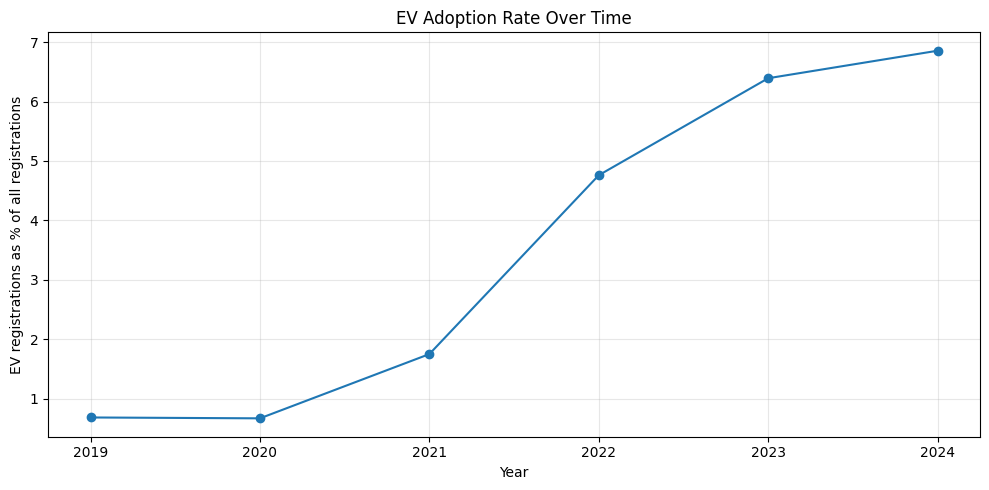

In [5]:
# 7. Overall registrations and EV registrations by year
annual = df.groupby("year").agg(
    total_registrations=("registrations", "sum"),
    ev_registrations=("registrations", lambda s: s[df.loc[s.index, "is_ev"]].sum())
).reset_index()

annual["ev_adoption_rate"] = annual["ev_registrations"] / annual["total_registrations"]

display(annual)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(annual["year"], annual["ev_adoption_rate"] * 100, marker="o")
ax.set_title("EV Adoption Rate Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("EV registrations as % of all registrations")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


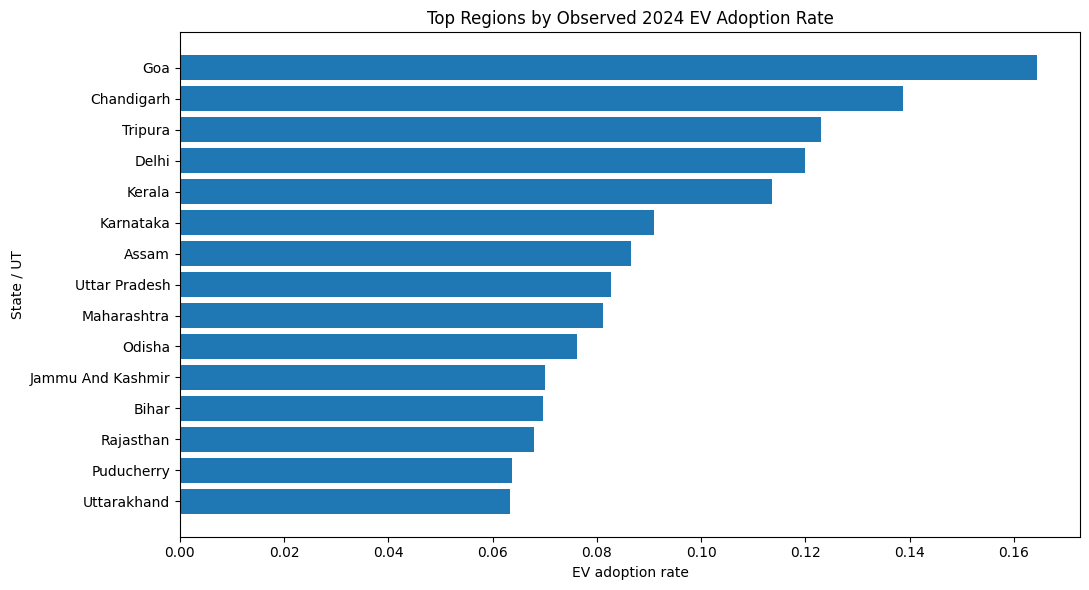

,state_name,total_registrations,ev_registrations,ev_adoption_rate
8,Goa,34992,5754,0.1644
5,Chandigarh,17658,2450,0.1387
30,Tripura,26387,3243,0.1229
7,Delhi,286459,34343,0.1199
15,Kerala,311396,35344,0.1135
14,Karnataka,797364,72539,0.0910
3,Assam,289591,25062,0.0865
31,Uttar Pradesh,1575932,130189,0.0826
18,Maharashtra,1162110,94227,0.0811
23,Odisha,389605,29710,0.0763


In [6]:
# 8. EV registrations by state in the latest observed period
state_2024 = df[df["year"] == 2024].groupby("state_name").agg(
    total_registrations=("registrations", "sum"),
    ev_registrations=("registrations", lambda s: s[df.loc[s.index, "is_ev"]].sum())
).reset_index()

state_2024["ev_adoption_rate"] = (
    state_2024["ev_registrations"] / state_2024["total_registrations"]
)

top_share = state_2024.sort_values("ev_adoption_rate", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(11, 6))
plot_data = top_share.sort_values("ev_adoption_rate")
ax.barh(plot_data["state_name"], plot_data["ev_adoption_rate"])
ax.set_title("Top Regions by Observed 2024 EV Adoption Rate")
ax.set_xlabel("EV adoption rate")
ax.set_ylabel("State / UT")
plt.tight_layout()
plt.show()

display(top_share)


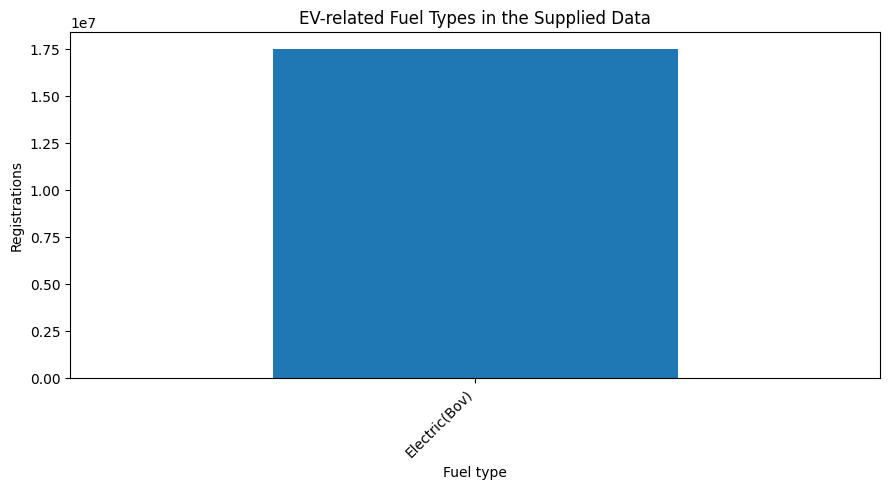

,registrations
fuel_type,
Electric(Bov),17524732


In [ ]:
# 9. EV registrations by fuel type
ev_fuel = df[df["is_ev"]].groupby("fuel_type")["registrations"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
ev_fuel.plot(kind="bar")
plt.title("EV-related Fuel Types in the Data")
plt.ylabel("Registrations")
plt.xlabel("Fuel type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(ev_fuel.to_frame("registrations"))


## 4. Feature Engineering

We use only information available **before the target period** to predict 2024:
- 2019–2023 EV adoption rates
- 2021–2023 average EV adoption
- 2022→2023 adoption-rate change
- 2022→2023 EV-registration growth
- 2022→2023 total-registration growth
- 2021→2023 EV-registration CAGR

The 2024 target is never to the model as an explanatory variable.


In [8]:
# 10. Create annual state-level measures
annual_state = df.groupby(["state_name", "year"]).agg(
    total_registrations=("registrations", "sum"),
    ev_registrations=("registrations", lambda s: s[df.loc[s.index, "is_ev"]].sum()),
    office_count=("office_name", "nunique")
).reset_index()

annual_state["ev_adoption_rate"] = (
    annual_state["ev_registrations"] / annual_state["total_registrations"]
)

wide = annual_state.pivot(
    index="state_name",
    columns="year",
    values=["total_registrations", "ev_registrations", "ev_adoption_rate", "office_count"]
)
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.reset_index()

# Compact explanatory feature set: historical information only.
model_data = wide[["state_name"]].copy()
for col in [
    "ev_adoption_rate_2021", "ev_adoption_rate_2022", "ev_adoption_rate_2023",
    "ev_registrations_2023", "total_registrations_2023", "office_count_2023"
]:
    model_data[col] = wide[col]

model_data["ev_share_avg_2021_23"] = model_data[
    ["ev_adoption_rate_2021", "ev_adoption_rate_2022", "ev_adoption_rate_2023"]
].mean(axis=1)

model_data["ev_share_change_22_23"] = (
    model_data["ev_adoption_rate_2023"] - model_data["ev_adoption_rate_2022"]
)

# Growth features. Replace undefined growth caused by a zero denominator with 0.
ev22 = wide["ev_registrations_2022"].replace(0, np.nan)
tot22 = wide["total_registrations_2022"].replace(0, np.nan)

model_data["ev_reg_growth_22_23"] = (
    (wide["ev_registrations_2023"] / ev22) - 1
).replace([np.inf, -np.inf], np.nan).fillna(0)

model_data["total_reg_growth_22_23"] = (
    (wide["total_registrations_2023"] / tot22) - 1
).replace([np.inf, -np.inf], np.nan).fillna(0)

ev21 = wide["ev_registrations_2021"].replace(0, np.nan)
model_data["ev_cagr_21_23"] = (
    (wide["ev_registrations_2023"] / ev21) ** (1/2) - 1
).replace([np.inf, -np.inf], np.nan).fillna(0)

# 2024 is the outcome period.
target = wide[[
    "state_name", "ev_adoption_rate_2024", "ev_registrations_2024",
    "total_registrations_2024"
]].copy()

model_data = model_data.merge(target, on="state_name", how="inner")

# Remove any remaining missing/infinite feature values.
feature_cols = [
    "ev_adoption_rate_2021", "ev_adoption_rate_2022", "ev_adoption_rate_2023",
    "ev_registrations_2023", "total_registrations_2023", "office_count_2023",
    "ev_share_avg_2021_23", "ev_share_change_22_23",
    "ev_reg_growth_22_23", "total_reg_growth_22_23", "ev_cagr_21_23"
]

model_data[feature_cols] = model_data[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)

print("Modeling dataset shape:", model_data.shape)
display(model_data.head())


Modeling dataset shape: (34, 15)


,state_name,ev_adoption_rate_2021,ev_adoption_rate_2022,ev_adoption_rate_2023,ev_registrations_2023,total_registrations_2023,office_count_2023,ev_share_avg_2021_23,ev_share_change_22_23,ev_reg_growth_22_23,total_reg_growth_22_23,ev_cagr_21_23,ev_adoption_rate_2024,ev_registrations_2024,total_registrations_2024
0,Andaman And Nicobar Islands,0.0160,0.0033,0.0032,26.0000,"8,072.0000",1.0000,0.0075,-0.0000,0.1304,0.1425,-0.4684,0.0083,29.0000,"3,503.0000"
1,Andhra Pradesh,0.0174,0.0469,0.0372,"32,867.0000","884,442.0000",67.0000,0.0338,-0.0097,-0.9841,-0.9800,-0.8155,0.0620,"23,256.0000","375,397.0000"
2,Arunachal Pradesh,0.0175,0.0475,0.0638,"1,532,305.0000","24,027,454.0000",26.0000,0.0429,0.0163,0.4949,0.1127,1.1497,0.0010,15.0000,"15,664.0000"
3,Assam,0.0342,0.0795,0.0932,"59,885.0000","642,856.0000",31.0000,0.0689,0.0137,0.4171,0.2087,0.9725,0.0865,"25,062.0000","289,591.0000"
4,Bihar,0.0229,0.0494,0.0685,"88,218.0000","1,288,278.0000",38.0000,0.0469,0.0191,0.5823,0.1405,0.9549,0.0697,"40,666.0000","583,704.0000"


### Target construction

We use two complementary targets:

**Regression target**
- `ev_adoption_rate_2024`: continuous EV adoption rate.

**Classification target**
- `high_adoption = 1` if the 2024 EV adoption rate is at or above the 75th percentile across observed regions.
- `high_adoption = 0` otherwise.

**Which regions should be flagged as high EV-adoption regions?**


In [9]:
# 11. Create the classification target
threshold = model_data["ev_adoption_rate_2024"].quantile(0.75)

model_data["high_adoption"] = (
    model_data["ev_adoption_rate_2024"] >= threshold
).astype(int)

print(f"High-adoption threshold (75th percentile): {threshold:.2%}")
display(model_data["high_adoption"].value_counts().rename(index={0: "Normal", 1: "High"}).to_frame("regions"))


High-adoption threshold (75th percentile): 7.99%


,regions
high_adoption,
Normal,25
High,9


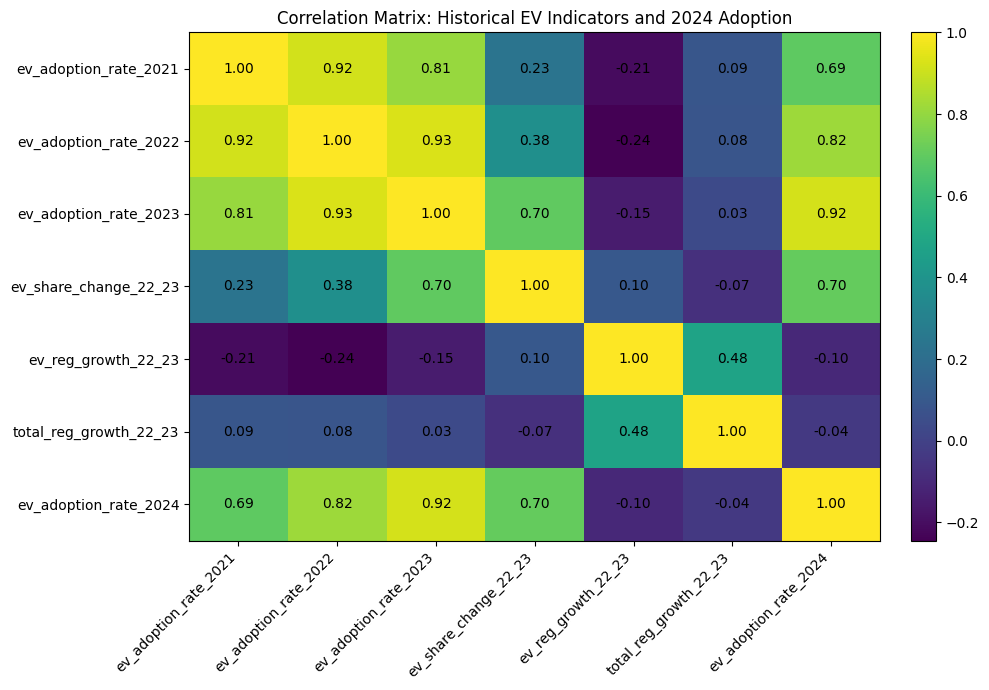

In [10]:
# 12. Correlation view of the key historical variables
corr_cols = [
    "ev_adoption_rate_2021", "ev_adoption_rate_2022",
    "ev_adoption_rate_2023", "ev_share_change_22_23",
    "ev_reg_growth_22_23", "total_reg_growth_22_23",
    "ev_adoption_rate_2024"
]

corr = model_data[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr.values, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Matrix: Historical EV Indicators and 2024 Adoption")

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 5. Regression: Predicting the 2024 EV Adoption Rate

A regression model gives a continuous estimate of expected EV adoption.
We start with **Linear Regression** as a transparent baseline, then compare it with ensemble regressors.


In [11]:
# 13. Regression train/test split
X = model_data[feature_cols]
y_reg = model_data["ev_adoption_rate_2024"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.25, random_state=42
)

linear_reg = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

rf_reg = RandomForestRegressor(
    n_estimators=300, max_features=0.7, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)

gb_reg = GradientBoostingRegressor(
    n_estimators=150, max_depth=2, learning_rate=0.05,
    random_state=42
)

reg_models = {
    "Linear Regression": linear_reg,
    "Random Forest": rf_reg,
    "Gradient Boosting": gb_reg
}

reg_results = []

for name, model in reg_models.items():
    model.fit(X_train_r, y_train_r)
    pred = np.maximum(model.predict(X_test_r), 0)
    reg_results.append({
        "Model": name,
        "R2": r2_score(y_test_r, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, pred)),
        "MAE": mean_absolute_error(y_test_r, pred)
    })

reg_board = pd.DataFrame(reg_results).sort_values("RMSE")
display(reg_board)


,Model,R2,RMSE,MAE
1,Random Forest,0.6658,0.0283,0.0222
2,Gradient Boosting,0.6072,0.0307,0.0245
0,Linear Regression,0.5991,0.0310,0.0211


## 6. Classification: Predicting High-Adoption Regions

Classification directly answers the infrastructure-planning question.

Models:
1. Logistic Regression — interpretable baseline
2. Decision Tree — easy-to-explain business rules
3. Random Forest — bagging/variance reduction
4. Gradient Boosting — sequential learning of errors

The evaluation uses **Accuracy** and **ROC-AUC**, with the same train/test split and random state for fair comparison.


In [12]:
# 14. Classification train/test split
y_cls = model_data["high_adoption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cls, test_size=0.25, random_state=42, stratify=y_cls
)

log_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

tree_model = DecisionTreeClassifier(
    max_depth=3, min_samples_leaf=2, random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=300, max_features=0.7, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)

gb_model = GradientBoostingClassifier(
    n_estimators=150, max_depth=2, learning_rate=0.05,
    random_state=42
)

cls_models = {
    "Logistic Regression": log_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

cls_results = []

for name, model in cls_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    cls_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, prob)
    })

cls_board = pd.DataFrame(cls_results).sort_values("ROC_AUC", ascending=False)
display(cls_board)


,Model,Accuracy,ROC_AUC
0,Logistic Regression,1.0000,1.0000
1,Decision Tree,1.0000,1.0000
2,Random Forest,1.0000,1.0000
3,Gradient Boosting,1.0000,1.0000


                 precision    recall  f1-score   support

Normal adoption       1.00      1.00      1.00         7
  High adoption       1.00      1.00      1.00         2

       accuracy                           1.00         9
      macro avg       1.00      1.00      1.00         9
   weighted avg       1.00      1.00      1.00         9



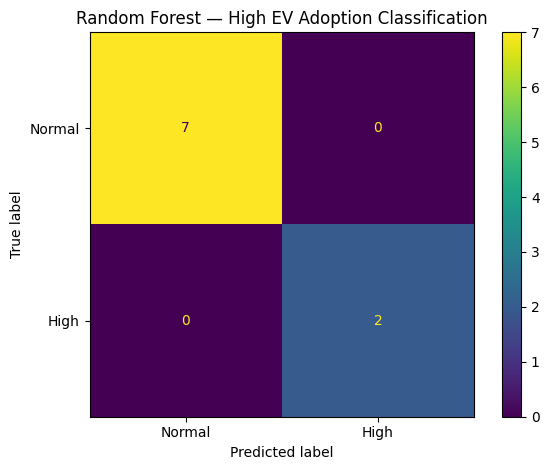

In [13]:
# 15. Confusion matrix and classification report for the Random Forest
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print(classification_report(
    y_test, rf_pred,
    target_names=["Normal adoption", "High adoption"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["Normal", "High"]
)
plt.title("Random Forest — High EV Adoption Classification")
plt.tight_layout()
plt.show()


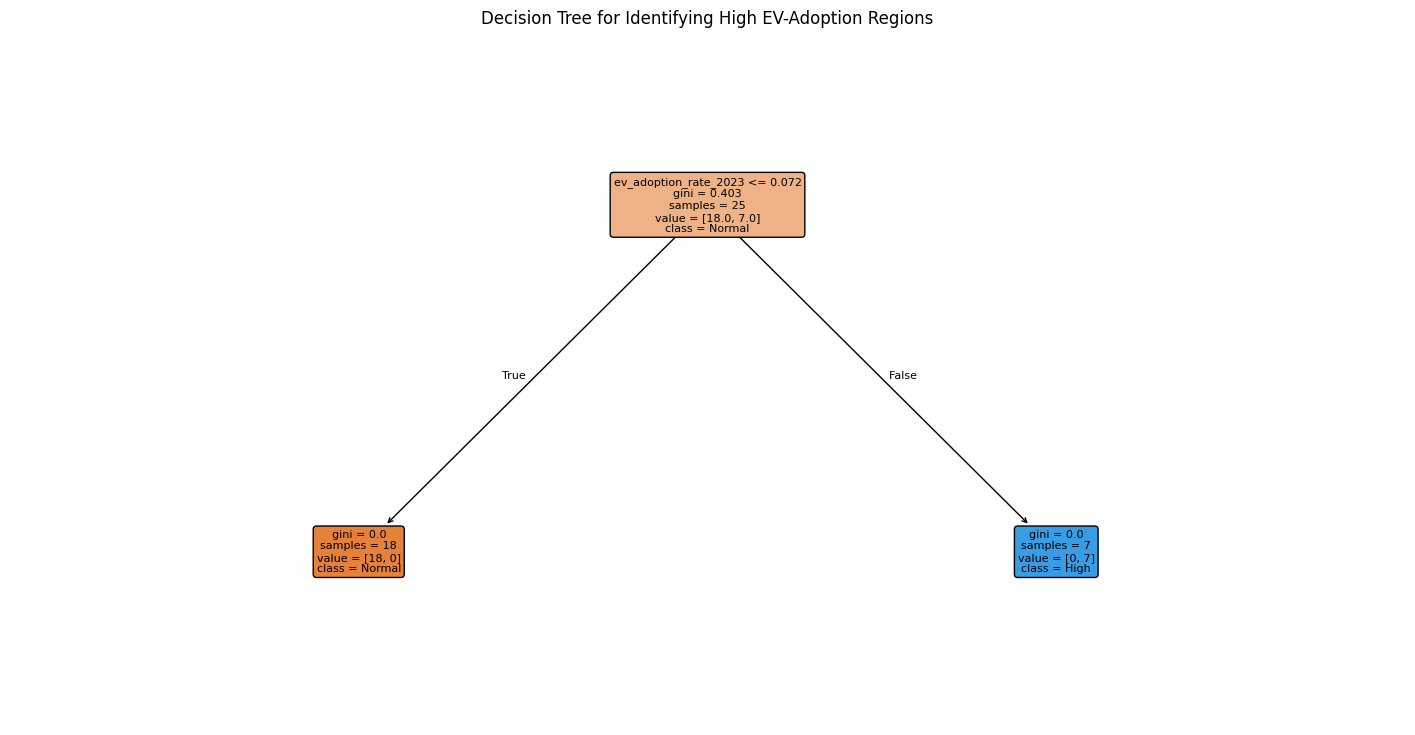

In [14]:
# 16. Decision Tree: interpretable business rules
tree_model.fit(X_train, y_train)

plt.figure(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=feature_cols,
    class_names=["Normal", "High"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree for Identifying High EV-Adoption Regions")
plt.show()


In [15]:
# 17. Cross-validation: check whether the result depends on one lucky split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in cls_models.items():
    scores = cross_val_score(model, X, y_cls, cv=cv, scoring="roc_auc")
    cv_rows.append({
        "Model": name,
        "Mean CV ROC-AUC": scores.mean(),
        "CV Std Dev": scores.std(),
        "Fold Scores": np.round(scores, 3)
    })

cv_board = pd.DataFrame(cv_rows).sort_values("Mean CV ROC-AUC", ascending=False)
display(cv_board)


,Model,Mean CV ROC-AUC,CV Std Dev,Fold Scores
0,Logistic Regression,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
2,Random Forest,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
3,Gradient Boosting,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
1,Decision Tree,0.9800,0.0400,"[1.0, 1.0, 1.0, 0.9, 1.0]"


## 7. Feature Importance

For tree-based models, feature importance helps answer the management question:

> **Which historical signals are most useful for anticipating high EV adoption?**

The most useful variables should be interpreted as predictive signals, not automatically as causal drivers.


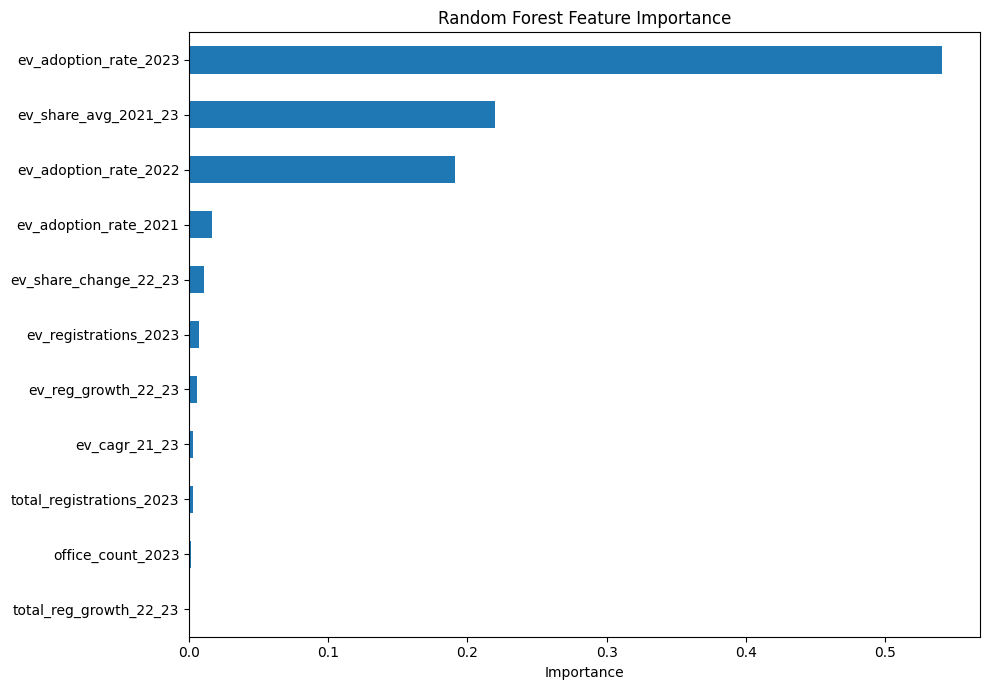

,importance
ev_adoption_rate_2023,0.5413
ev_share_avg_2021_23,0.2201
ev_adoption_rate_2022,0.1913
ev_adoption_rate_2021,0.0162
ev_share_change_22_23,0.0104
ev_registrations_2023,0.0071
ev_reg_growth_22_23,0.0057
ev_cagr_21_23,0.0031
total_registrations_2023,0.0030
office_count_2023,0.0011


In [16]:
# 18. Random Forest feature importance
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))
rf_importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(rf_importance.sort_values(ascending=False).to_frame("importance"))


## 8. Final Regional Prediction

For deployment-style scoring, we retrain the selected classification model on **all available historical states** and generate a high-adoption probability for every region.

Because this is a small state-level dataset, model performance is treated as **directional rather than production-grade**. A real infrastructure programme should refresh the model with a longer time series, vehicle category data, population/vehicle ownership, income, road traffic, electricity demand and existing charging-station locations.


In [17]:
# 19. Final scoring of all regions
# Logistic regression is retained as an interpretable final model;
# Random Forest is also used for a non-linear probability estimate.
final_log = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
final_rf = RandomForestClassifier(
    n_estimators=500, max_features=0.7, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)

final_log.fit(X, y_cls)
final_rf.fit(X, y_cls)

scored = model_data[[
    "state_name", "ev_adoption_rate_2024", "ev_registrations_2024",
    "total_registrations_2024"
]].copy()

scored["logistic_high_adoption_probability"] = final_log.predict_proba(X)[:, 1]
scored["rf_high_adoption_probability"] = final_rf.predict_proba(X)[:, 1]

# A simple consensus flag: both models assign high probability.
scored["priority_flag"] = (
    (scored["logistic_high_adoption_probability"] >= 0.50) &
    (scored["rf_high_adoption_probability"] >= 0.50)
).astype(int)

scored = scored.sort_values(
    ["priority_flag", "rf_high_adoption_probability", "ev_adoption_rate_2024"],
    ascending=[False, False, False]
)

display(scored.head(20))


,state_name,ev_adoption_rate_2024,ev_registrations_2024,total_registrations_2024,logistic_high_adoption_probability,rf_high_adoption_probability,priority_flag
8,Goa,0.1644,"5,754.0000","34,992.0000",0.9532,0.9841,1
14,Karnataka,0.0910,"72,539.0000","797,364.0000",0.7867,0.9825,1
5,Chandigarh,0.1387,"2,450.0000","17,658.0000",0.9782,0.9698,1
30,Tripura,0.1229,"3,243.0000","26,387.0000",0.9968,0.9653,1
3,Assam,0.0865,"25,062.0000","289,591.0000",0.8113,0.9615,1
7,Delhi,0.1199,"34,343.0000","286,459.0000",0.9791,0.9402,1
31,Uttar Pradesh,0.0826,"130,189.0000","1,575,932.0000",0.6459,0.8958,1
15,Kerala,0.1135,"35,344.0000","311,396.0000",0.9399,0.8571,1
18,Maharashtra,0.0811,"94,227.0000","1,162,110.0000",0.3753,0.8048,0
32,Uttarakhand,0.0633,"6,796.0000","107,288.0000",0.1944,0.2536,0


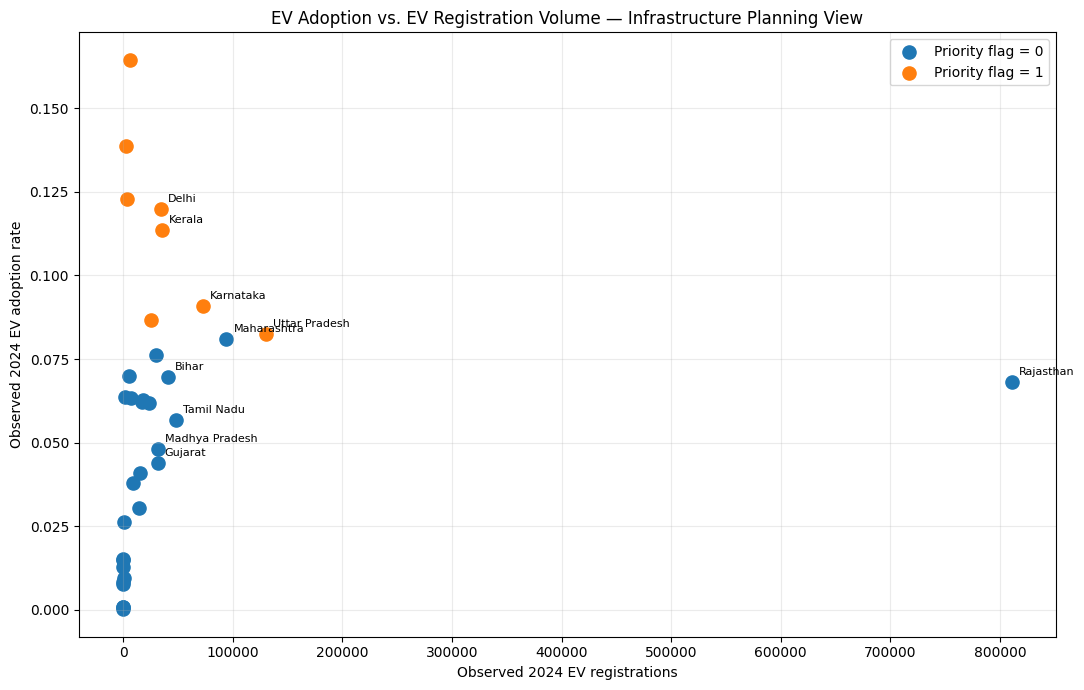

In [18]:
# 20. Business view: adoption rate vs. EV volume
plot_df = scored.copy()

fig, ax = plt.subplots(figsize=(11, 7))
for flag, group in plot_df.groupby("priority_flag"):
    ax.scatter(
        group["ev_registrations_2024"],
        group["ev_adoption_rate_2024"],
        s=90,
        label=f"Priority flag = {flag}"
    )

# Label the most important regions by EV registrations.
for _, row in plot_df.nlargest(10, "ev_registrations_2024").iterrows():
    ax.annotate(
        row["state_name"],
        (row["ev_registrations_2024"], row["ev_adoption_rate_2024"]),
        xytext=(5, 5), textcoords="offset points", fontsize=8
    )

ax.set_title("EV Adoption vs. EV Registration Volume — Infrastructure Planning View")
ax.set_xlabel("Observed 2024 EV registrations")
ax.set_ylabel("Observed 2024 EV adoption rate")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


Planning matrix

- **High adoption + high EV volume:** strongest immediate candidates for charging-infrastructure expansion.
- **High adoption + lower EV volume:** emerging EV markets; monitor and plan targeted charging coverage.
- **Lower adoption + high EV volume:** large vehicle markets where even moderate EV penetration can create substantial charging demand.
- **Lower adoption + lower volume:** lower immediate priority, but continue monitoring growth.

This prevents mistake of using **percentage adoption alone**. A small region can have a very high EV share but still require fewer chargers than a large region with a lower share.


## 9. Regional Segmentation with K-Means + PCA

As an additional unsupervised-learning layer, states are grouped using historical EV indicators only.

This follows the class clustering workflow:
- select meaningful numeric behaviour variables
- standardise them because variables are on different scales
- compare several values of *k*
- use silhouette score
- visualise clusters using PCA

The clusters are **profiles**, not predictions.


In [19]:
# 21. K-Means clustering of regional EV profiles
cluster_features = [
    "ev_adoption_rate_2021",
    "ev_adoption_rate_2022",
    "ev_adoption_rate_2023",
    "ev_registrations_2023",
    "total_registrations_2023",
    "ev_share_change_22_23"
]

X_cluster = model_data[cluster_features].replace([np.inf, -np.inf], np.nan).fillna(0)

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

silhouette_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_cluster_scaled)
    silhouette_rows.append({
        "k": k,
        "silhouette_score": silhouette_score(X_cluster_scaled, labels)
    })

silhouette_table = pd.DataFrame(silhouette_rows)
display(silhouette_table)

best_k = int(
    silhouette_table.loc[silhouette_table["silhouette_score"].idxmax(), "k"]
)

print("Best k by silhouette score:", best_k)


,k,silhouette_score
0,2,0.3998
1,3,0.4712
2,4,0.4475
3,5,0.4777
4,6,0.4718


Best k by silhouette score: 5


In [20]:
# 22. Fit final K-Means and profile the clusters
kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=42)
model_data["cluster"] = kmeans.fit_predict(X_cluster_scaled)

cluster_profile = model_data.groupby("cluster")[[
    "ev_adoption_rate_2021",
    "ev_adoption_rate_2022",
    "ev_adoption_rate_2023",
    "ev_registrations_2023",
    "total_registrations_2023",
    "ev_share_change_22_23",
    "ev_adoption_rate_2024"
]].mean().round(4)

display(cluster_profile)

display(
    model_data[["state_name", "cluster", "ev_adoption_rate_2023", "ev_adoption_rate_2024"]]
    .sort_values(["cluster", "ev_adoption_rate_2024"], ascending=[True, False])
)


,ev_adoption_rate_2021,ev_adoption_rate_2022,ev_adoption_rate_2023,ev_registrations_2023,total_registrations_2023,ev_share_change_22_23,ev_adoption_rate_2024
cluster,,,,,,,
0,0.0477,0.1009,0.1142,"49,540.3333","470,127.0000",0.0134,0.1098
1,0.0154,0.0431,0.0569,"74,269.0625","1,182,114.6250",0.0138,0.0632
2,0.0038,0.0044,0.0069,"2,338.9000","129,896.7000",0.0026,0.0127
3,0.0178,0.0482,0.0637,"1,625,981.0000","25,537,299.0000",0.0155,0.0345
4,0.0194,0.0603,0.1123,"30,558.6667","297,845.0000",0.0520,0.1389


,state_name,cluster,ev_adoption_rate_2023,ev_adoption_rate_2024
30,Tripura,0,0.1376,0.1229
7,Delhi,0,0.1120,0.1199
3,Assam,0,0.0932,0.0865
14,Karnataka,1,0.0874,0.0910
31,Uttar Pradesh,1,0.0808,0.0826
18,Maharashtra,1,0.0758,0.0811
23,Odisha,1,0.0651,0.0763
12,Jammu And Kashmir,1,0.0568,0.0700
4,Bihar,1,0.0685,0.0697
24,Puducherry,1,0.0476,0.0636


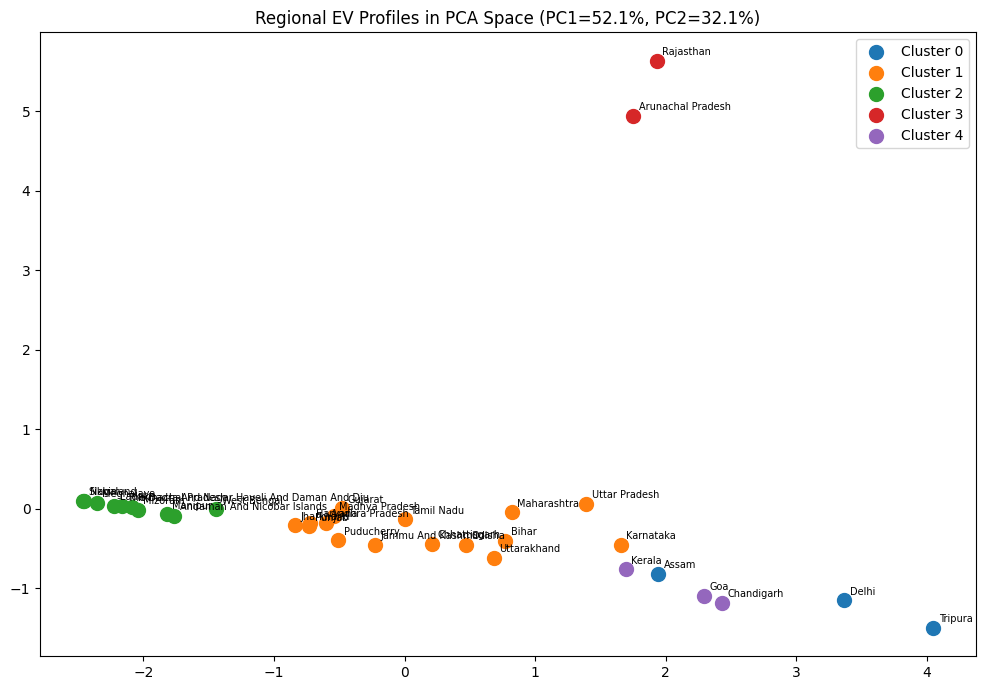

In [21]:
# 23. PCA visualisation of regional profiles
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_cluster_scaled)

pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "cluster": model_data["cluster"].astype(str).values,
    "state_name": model_data["state_name"].values
})

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_name, group in pca_df.groupby("cluster"):
    ax.scatter(group["PC1"], group["PC2"], s=100, label=f"Cluster {cluster_name}")

for _, row in pca_df.iterrows():
    ax.annotate(
        row["state_name"], (row["PC1"], row["PC2"]),
        xytext=(4, 4), textcoords="offset points", fontsize=7
    )

ax.set_title(
    f"Regional EV Profiles in PCA Space "
    f"(PC1={pca.explained_variance_ratio_[0]:.1%}, "
    f"PC2={pca.explained_variance_ratio_[1]:.1%})"
)
ax.legend()
plt.tight_layout()
plt.show()


## 10. Managerial Interpretation and Recommendations

### Recommended infrastructure strategy

1. **Prioritise high-adoption/high-volume regions first.**
   These regions combine strong EV penetration with a large number of EV registrations.

2. **Use predictive probability as an early-warning signal.**
   Regions with a high predicted probability but lower current adoption can be treated as emerging markets for charging infrastructure.

3. **Do not allocate chargers using EV share alone.**
   Absolute EV registrations matter because charging demand is a function of both penetration and market size.

4. **Use RTO/office-level data for the next stage.**
   Once state-level priority regions are identified, the same framework can be applied to `office_name` / `office_code` to locate specific districts or RTO catchments.

5. **Add external explanatory variables before operational deployment.**
   Useful additions include population, vehicle ownership, urbanisation, income, electricity load, road traffic, highway density, existing charging stations, renewable generation and commercial-fleet activity.

### Key limitations

- The data ends in **May 2024**, so 2024 is not a full-year observation.
- The analysis is based on registration data, not actual charging sessions or electricity consumption.
- State-level sample size is small (34 observed regions), so model scores can look stronger than they would on a much larger out-of-sample dataset.
- Registration coverage and reporting practices can change over time.
- Correlation/predictive importance does not establish causality.
- The FAME 31-Dec-2024 segment dataset named in the business context is not the data.

### Final business output

The final output is the `scored` table, which provides:
- observed 2024 EV adoption rate
- observed EV registrations
- logistic-regression high-adoption probability
- Random-Forest high-adoption probability
- a consensus `priority_flag`

This can be converted into a dashboard or map for government/utility planning.


In [22]:
# 24. Final shortlist for presentation
presentation_table = scored.loc[
    scored["priority_flag"] == 1,
    [
        "state_name",
        "ev_registrations_2024",
        "ev_adoption_rate_2024",
        "logistic_high_adoption_probability",
        "rf_high_adoption_probability"
    ]
].copy()

presentation_table = presentation_table.sort_values(
    "rf_high_adoption_probability", ascending=False
)

presentation_table["ev_adoption_rate_2024"] = (
    presentation_table["ev_adoption_rate_2024"] * 100
).round(2)

presentation_table["logistic_high_adoption_probability"] = (
    presentation_table["logistic_high_adoption_probability"] * 100
).round(1)

presentation_table["rf_high_adoption_probability"] = (
    presentation_table["rf_high_adoption_probability"] * 100
).round(1)

presentation_table.columns = [
    "Region",
    "Observed EV registrations",
    "Observed EV adoption (%)",
    "Logistic high-adoption probability (%)",
    "RF high-adoption probability (%)"
]

display(presentation_table)


,Region,Observed EV registrations,Observed EV adoption (%),Logistic high-adoption probability (%),RF high-adoption probability (%)
8,Goa,"5,754.0000",16.4400,95.3000,98.4000
14,Karnataka,"72,539.0000",9.1000,78.7000,98.2000
5,Chandigarh,"2,450.0000",13.8700,97.8000,97.0000
30,Tripura,"3,243.0000",12.2900,99.7000,96.5000
3,Assam,"25,062.0000",8.6500,81.1000,96.2000
7,Delhi,"34,343.0000",11.9900,97.9000,94.0000
31,Uttar Pradesh,"130,189.0000",8.2600,64.6000,89.6000
15,Kerala,"35,344.0000",11.3500,94.0000,85.7000
